# Feature Selection — Extended Lab: Leakage-free selection, a new model, and a performance study

The original notebook (`Feature_Selection.ipynb`) compares feature-selection methods on the breast-cancer dataset with a RandomForest.
This extension keeps the same families of methods (filter / wrapper / embedded) but changes **what** we work on and **how** we judge it:

| | original lab | this extension |
|---|---|---|
| dataset | Breast Cancer Wisconsin (569 rows, 30 features) | **UCI Spambase** (4,601 rows, 57 features) |
| model | `RandomForestClassifier` | **`HistGradientBoostingClassifier`** (RF and LogisticRegression kept as references) |
| where selection happens | on the full dataset / before the split → test rows leak into the choice of features | **inside a `Pipeline`**, re-fit on every CV training fold only |
| evaluation | one 80/20 split (114 test rows) | 5-fold stratified CV on the training set, mean ± std, then **one** look at a locked 20% test set |
| ROC-AUC | computed from hard 0/1 predictions | computed from **predicted probabilities** |
| how many features (`k`) | hard-coded 20 | chosen by a CV sweep + one-standard-error rule |
| what "better" means | accuracy / F1 only | accuracy **and** cost: fit time, inference latency, model size, number of features, selection stability |

Sections
1. Why the original results can't be trusted as-is (noise + leakage)
2. Data and protocol
3. New model vs. the original model
4. Choosing `k` with a CV sweep
5. Head-to-head comparison of 10 selection methods (quality **and** performance)
6. Selection stability across folds
7. Pick a winner with an explicit rule, then score it once on the locked test set

In [3]:
import pickle
import time
import warnings
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import (RFE, SelectFromModel, SelectKBest, SequentialFeatureSelector, chi2,
                                       f_classif, mutual_info_classif)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import (RepeatedStratifiedKFold, StratifiedKFold, cross_val_score, cross_validate,
                                     train_test_split)
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

import sys
sys.path.insert(0, "src")
from fs_transformers import ColumnSubset, CorrelationFilter, PermutationImportanceSelector  # src/fs_transformers.py

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
REPORTS = Path("reports"); FIGS = REPORTS / "figures"; MODELS = Path("models")
for d in (REPORTS, FIGS, MODELS):
    d.mkdir(parents=True, exist_ok=True)
pd.set_option("display.precision", 4)

## 1. Why the original results can't be trusted as-is

### 1a. The differences are smaller than the noise
In the original notebook every method scores either 0.9649 or 0.9737 accuracy on the 114-row test set — that gap is **exactly one patient**.
Re-running the original "All features" vs "F-test top 20" comparison with 5×5 repeated stratified CV (selection inside the pipeline) shows how wide the spread really is.

In [4]:
bc = pd.read_csv("data/breast_cancer_data.csv").drop(columns=["Unnamed: 32", "id"])
bc_y = (bc.pop("diagnosis") == "M").astype(int)
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
rf_orig = RandomForestClassifier(criterion="entropy", random_state=47, n_jobs=-1)

rows = []
for name, est in {
    "All features (30)": make_pipeline(StandardScaler(), rf_orig),
    "F-test top 20": make_pipeline(StandardScaler(), SelectKBest(f_classif, k=20), rf_orig),
}.items():
    acc = cross_val_score(est, bc, bc_y, cv=rcv, scoring="accuracy", n_jobs=-1)
    rows.append({"setup": name, "acc_mean": acc.mean(), "acc_std": acc.std(), "acc_min": acc.min(), "acc_max": acc.max()})
pd.DataFrame(rows).set_index("setup")

,acc_mean,acc_std,acc_min,acc_max
setup,,,,
All features (30),0.9564,0.0205,0.9035,0.9912
F-test top 20,0.9582,0.0179,0.9211,0.9912


The fold-to-fold standard deviation (~2 points of accuracy) is larger than every gap in the original results table, so the
original ranking of methods is mostly noise. Everything below therefore reports **mean ± std over CV folds**.

### 1b. Selecting features on the full dataset leaks the answer
The original notebook computes correlations with the target on the full dataframe and calls `SelectKBest` before/outside the evaluation loop.
The cleanest way to see the damage is a dataset where there is **nothing** to learn: 200 rows, 2,000 pure-noise features, random labels. The honest answer is chance level (AUC ≈ 0.5).

In [6]:
rng = np.random.default_rng(SEED)
X_noise = rng.normal(size=(200, 2000))
y_noise = rng.integers(0, 2, size=200)
cv5 = StratifiedKFold(5, shuffle=True, random_state=SEED)
clf = LogisticRegression(max_iter=2000)

# WRONG: pick the 20 "best" features using all rows, then cross-validate
X_leaky = SelectKBest(f_classif, k=20).fit_transform(X_noise, y_noise)
auc_leaky = cross_val_score(clf, X_leaky, y_noise, cv=cv5, scoring="roc_auc")

# RIGHT: selection is a pipeline step, so it is re-fit on each training fold only
auc_clean = cross_val_score(make_pipeline(SelectKBest(f_classif, k=20), clf), X_noise, y_noise, cv=cv5, scoring="roc_auc")

leak_df = pd.DataFrame({"ROC-AUC mean": [auc_leaky.mean(), auc_clean.mean()], "ROC-AUC std": [auc_leaky.std(), auc_clean.std()]},
                       index=["select on all rows, then CV (original pattern)", "select inside Pipeline (this lab)"])
leak_df

,ROC-AUC mean,ROC-AUC std
"select on all rows, then CV (original pattern)",0.8748,0.0361
select inside Pipeline (this lab),0.6009,0.0458


Selecting before splitting reports a confident, completely fake signal on random data. Every selector in the rest of this notebook is therefore a `Pipeline` step.

## 2. Data and protocol

**UCI Spambase**: 4,601 e-mails, 57 numeric features (48 word frequencies, 6 character frequencies, 3 capital-letter run-length statistics), target = spam (39.4%).
It is a better feature-selection playground than breast cancer: twice as many features, many of them near-empty word counts, and 8× more rows so CV estimates are tighter.
`src/get_data.py` downloads it from UCI.

Protocol:
* 80/20 stratified split. The 20% **test set is locked** until section 7.
* Every comparison uses the same 5-fold stratified CV on the 80% training set.
* Primary metric: ROC-AUC from `predict_proba`. Also reported: F1, accuracy.

In [7]:
data_path = Path("data/spambase.csv")
if not data_path.exists():
    import subprocess, sys
    subprocess.run([sys.executable, "src/get_data.py"], check=True)

df = pd.read_csv(data_path)
X, y = df.drop(columns="is_spam"), df["is_spam"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
FEATURES = X.columns.to_numpy()
print(f"train {X_train.shape}, test {X_test.shape}, spam rate train {y_train.mean():.3f} / test {y_test.mean():.3f}")
print(f"features that are zero in >80% of training rows: {(X_train.eq(0).mean() > 0.8).sum()} / {X.shape[1]}")

train (3680, 57), test (921, 57), spam rate train 0.394 / test 0.394
features that are zero in >80% of training rows: 38 / 57


In [8]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {"roc_auc": "roc_auc", "f1": "f1", "accuracy": "accuracy"}

def new_model():
    '''The model this extension uses for every selection method.'''
    return HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, early_stopping=False, random_state=SEED)

def n_selected(pipe):
    '''Number of features that reach the final estimator of a fitted pipeline.'''
    return pipe[:-1].transform(X_train.iloc[:1]).shape[1] if len(pipe) > 1 else X_train.shape[1]

def selected_names(pipe):
    mask = np.ones(len(FEATURES), dtype=bool)
    for step in pipe[:-1]:
        if hasattr(step, "get_support"):
            sub = step.get_support()
            idx = np.flatnonzero(mask); mask[:] = False; mask[idx[sub]] = True
    return FEATURES[mask]

def run_cv(pipe):
    '''5-fold CV with timing; returns a dict of mean/std metrics plus the fitted fold pipelines.'''
    r = cross_validate(pipe, X_train, y_train, cv=CV, scoring=SCORING, return_estimator=True, n_jobs=1)
    out = {f"{m}": r[f"test_{m}"].mean() for m in SCORING} | {f"{m}_std": r[f"test_{m}"].std() for m in SCORING}
    out["fit_s"] = r["fit_time"].mean()
    out["n_features"] = np.mean([n_selected(p) for p in r["estimator"]])
    out["_folds"] = r["estimator"]
    return out

## 3. New model vs. the original model

Same CV folds, all 57 features. `HistGradientBoostingClassifier` bins features into histograms, handles the heavy zero-inflation of word counts natively, and needs no scaling.

In [9]:
baselines = {
    "RandomForest (original lab model)": Pipeline([("model", RandomForestClassifier(criterion="entropy", random_state=47, n_jobs=-1))]),
    "LogisticRegression": Pipeline([("scale", StandardScaler()), ("model", LogisticRegression(max_iter=3000))]),
    "HistGradientBoosting (new model)": Pipeline([("model", new_model())]),
}
base_res = {k: run_cv(v) for k, v in baselines.items()}
base_df = pd.DataFrame(base_res).T.drop(columns="_folds")[["roc_auc", "roc_auc_std", "f1", "f1_std", "accuracy", "fit_s"]].astype(float)
base_df

,roc_auc,roc_auc_std,f1,f1_std,accuracy,fit_s
RandomForest (original lab model),0.9860,0.0042,0.9367,0.0069,0.9508,0.0730
LogisticRegression,0.9705,0.0062,0.9000,0.0137,0.9228,0.0054
HistGradientBoosting (new model),0.9875,0.0031,0.9460,0.0117,0.9576,1.3467


HistGradientBoosting is the strongest of the three on every quality metric (AUC 0.9875 vs 0.9860, F1 0.946 vs 0.937, accuracy 0.958 vs 0.951 for the original RandomForest),
so it becomes the model each selection method below has to serve. It is not free: it takes ~20× longer to fit than the multi-threaded RF on this machine.
LogisticRegression is far behind (AUC 0.9705), which matters later: methods that pick features "for a linear model" (L1, SFS with LogReg) are not guaranteed to pick the right ones for boosted trees.

## 4. Choosing `k` instead of hard-coding 20

For the three univariate filters (ANOVA F, chi², mutual information) sweep `k` and record CV ROC-AUC. Then apply the
**one-standard-error rule**: take the smallest `k` whose mean AUC is within one standard error of the best `k`.

In [10]:
K_GRID = [3, 5, 8, 10, 15, 20, 25, 30, 40, 57]
filters = {
    "ANOVA F": f_classif,
    "chi2": chi2,
    "mutual info": partial(mutual_info_classif, random_state=SEED),
}
sweep_rows = []
for fname, score_fn in filters.items():
    for k in K_GRID:
        pipe = Pipeline([("select", SelectKBest(score_fn, k=k)), ("model", new_model())])
        auc = cross_val_score(pipe, X_train, y_train, cv=CV, scoring="roc_auc", n_jobs=-1)
        sweep_rows.append({"filter": fname, "k": k, "auc": auc.mean(), "se": auc.std(ddof=1) / np.sqrt(len(auc))})
sweep = pd.DataFrame(sweep_rows)
sweep.to_csv(REPORTS / "k_sweep.csv", index=False)

def one_se_k(g):
    best = g.loc[g.auc.idxmax()]
    return int(g[g.auc >= best.auc - best.se].k.min())

best_k = {f: one_se_k(g) for f, g in sweep.groupby("filter")}
print("k chosen by the one-SE rule:", best_k)
sweep.pivot(index="k", columns="filter", values="auc")

k chosen by the one-SE rule: {'ANOVA F': 40, 'chi2': 30, 'mutual info': 40}


filter,ANOVA F,chi2,mutual info
k,,,
3,0.8713,0.8747,0.9132
5,0.9089,0.9475,0.9328
8,0.9335,0.9630,0.9578
10,0.9550,0.9725,0.9647
15,0.9680,0.9792,0.9793
20,0.9731,0.9841,0.9811
25,0.9804,0.9848,0.9822
30,0.9849,0.9861,0.9854
40,0.9870,0.9869,0.9866


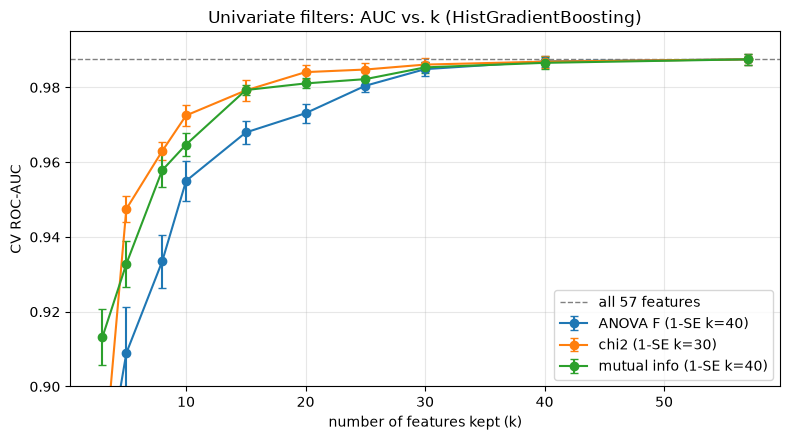

In [11]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for fname, g in sweep.groupby("filter"):
    ax.errorbar(g.k, g.auc, yerr=g.se, marker="o", capsize=3, label=f"{fname} (1-SE k={best_k[fname]})")
ax.axhline(base_df.loc["HistGradientBoosting (new model)", "roc_auc"], ls="--", c="grey", lw=1, label="all 57 features")
ax.set(xlabel="number of features kept (k)", ylabel="CV ROC-AUC", title="Univariate filters: AUC vs. k (HistGradientBoosting)")
ax.set_ylim(0.90, 0.995); ax.legend(loc="lower right"); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(FIGS / "k_sweep.png", dpi=150); plt.show()

* At small `k`, **chi² is clearly the best ranking** (AUC 0.948 with 5 features vs 0.909 for ANOVA F); ANOVA F is the worst filter whenever `k ≤ 20`.
* All three converge by `k ≈ 30–40`, and none beats all 57 features: boosted trees squeeze value out of many individually weak word counts.
* The original lab's fixed `k=20` would cost 0.003–0.014 AUC here depending on the filter. The 1-SE rule picks `k=30` for chi² and `k=40` for the other two, and `k=40` is reused for RFE and SFS below.

## 5. Head-to-head: 10 methods, quality **and** performance

Every method is a pipeline `selector → HistGradientBoosting`, evaluated on identical folds. New compared with the original lab:
* **Correlation filter as a transformer** (drops one of each pair with |r| > 0.9, fit on the training fold only).
* **chi²** — imported but never used in the original; valid here because all Spambase features are non-negative.
* **Mutual information** — catches non-linear relevance.
* **Sequential forward selection** — the wrapper the original lab describes but never runs.
* **Permutation importance of the boosted model itself**, measured on an internal validation split (impurity importances from RF are biased toward high-cardinality features).

For performance, each pipeline is re-fit on the full training set and then **frozen into a serving model**: a plain column subset + HistGradientBoosting
refit on just the selected columns. Why: a first run of this notebook showed `SelectFromModel(RandomForest)` made inference **3× slower** than using all features,
because it recomputes the forest's importances on every `transform`. The selector is a training-time tool; production only needs the column list.

Timed single-threaded (one serving worker; multi-threaded timings were dominated by OpenMP scheduling noise), on test-set features (no labels used):
* `fit_s` — CV fit time of the whole selection pipeline (the cost of *running* the method), `serve_fit_s` — retraining the frozen model
* `pipeline_batch_ms` — 921 rows through the un-frozen pipeline, `batch_ms` / `single_row_ms` — the frozen serving model
* `pipeline_kb` / `model_kb` — pickled size before / after freezing

In [ ]:
k_f, k_chi, k_mi = best_k["ANOVA F"], best_k["chi2"], best_k["mutual info"]
lr = lambda **kw: LogisticRegression(max_iter=3000, **kw)

methods = {
    "All features":            [],
    "Correlation filter |r|>0.9": [("select", CorrelationFilter(0.9))],
    f"ANOVA F (k={k_f})":      [("select", SelectKBest(f_classif, k=k_f))],
    f"chi2 (k={k_chi})":       [("select", SelectKBest(chi2, k=k_chi))],
    f"Mutual info (k={k_mi})": [("select", SelectKBest(partial(mutual_info_classif, random_state=SEED), k=k_mi))],
    f"RFE ExtraTrees (k={k_mi})": [("select", RFE(ExtraTreesClassifier(200, random_state=SEED, n_jobs=-1), n_features_to_select=k_mi, step=3))],
    f"Forward SFS LogReg (k={k_mi})": [("scale", StandardScaler()),
                                        ("select", SequentialFeatureSelector(lr(), n_features_to_select=k_mi, cv=3, scoring="roc_auc", n_jobs=-1))],
    "RF importance > median":  [("select", SelectFromModel(RandomForestClassifier(200, random_state=SEED, n_jobs=-1), threshold="median"))],
    "L1 LogReg (C=0.05)":      [("scale", StandardScaler()),
                                ("select", SelectFromModel(lr(l1_ratio=1.0, C=0.05, solver="liblinear")))],
    "HGB permutation importance": [("select", PermutationImportanceSelector(new_model()))],
}
pipelines = {name: Pipeline(steps + [("model", new_model())]) for name, steps in methods.items()}

def time_it(fn, repeats, warmup=3):
    for _ in range(warmup):
        fn()
    ts = []
    for _ in range(repeats):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    return float(np.median(ts))


def serving_model(pipe):
    '''Freeze a fitted selection pipeline into column-subset + model, refit on the raw selected columns.
    HistGradientBoosting bins on quantiles, so the scaling some selectors needed doesn't change the model.'''
    return Pipeline([("columns", ColumnSubset(list(selected_names(pipe)))), ("model", new_model())])


results, final_pipes, serving = {}, {}, {}
row = X_test.iloc[[0]]
for name, pipe in pipelines.items():
    t0 = time.perf_counter()
    res = run_cv(pipe)
    final_pipes[name] = final = clone(pipe).fit(X_train, y_train)
    srv = serving_model(final)
    # All timing single-threaded: stable numbers and a fair proxy for one serving worker.
    with threadpool_limits(limits=1):
        res["serve_fit_s"] = time_it(lambda: srv.fit(X_train, y_train), repeats=3, warmup=0)
        res["pipeline_batch_ms"] = 1000 * time_it(lambda: final.predict_proba(X_test), 30)
        res["batch_ms"] = 1000 * time_it(lambda: srv.predict_proba(X_test), 30)
        res["single_row_ms"] = 1000 * time_it(lambda: srv.predict_proba(row), 300)
    res["pipeline_kb"] = len(pickle.dumps(final)) / 1024
    res["model_kb"] = len(pickle.dumps(srv)) / 1024
    serving[name] = srv
    results[name] = res
    print(f"{name:32s} AUC {res['roc_auc']:.4f} ± {res['roc_auc_std']:.4f}  feats {res['n_features']:5.1f}  ({time.perf_counter()-t0:.0f}s)")

All features                     AUC 0.9875 ± 0.0031  feats  57.0  (13s)
Correlation filter |r|>0.9       AUC 0.9875 ± 0.0031  feats  55.6  (11s)
ANOVA F (k=40)                   AUC 0.9870 ± 0.0029  feats  40.0  (10s)
chi2 (k=30)                      AUC 0.9861 ± 0.0033  feats  30.0  (11s)


In [10]:
cols = ["n_features", "roc_auc", "roc_auc_std", "f1", "accuracy", "fit_s", "serve_fit_s", "pipeline_batch_ms", "batch_ms", "single_row_ms", "pipeline_kb", "model_kb"]
cmp_df = pd.DataFrame(results).T[cols].astype(float).sort_values("roc_auc", ascending=False)
base = cmp_df.loc["All features"]
cmp_df["feature_reduction"] = 1 - cmp_df.n_features / base.n_features
cmp_df["batch_speedup"] = base.batch_ms / cmp_df.batch_ms
cmp_df.to_csv(REPORTS / "method_comparison.csv")
cmp_df.style.format({c: "{:.4f}" for c in ["roc_auc", "roc_auc_std", "f1", "accuracy"]} |
                    {"n_features": "{:.1f}", "fit_s": "{:.2f}", "serve_fit_s": "{:.2f}", "pipeline_batch_ms": "{:.1f}",
                     "batch_ms": "{:.1f}", "single_row_ms": "{:.2f}", "pipeline_kb": "{:.0f}", "model_kb": "{:.0f}", "feature_reduction": "{:.0%}", "batch_speedup": "{:.2f}x"}) \
            .background_gradient(subset=["roc_auc"], cmap="Greens")

,n_features,roc_auc,roc_auc_std,f1,accuracy,fit_s,serve_fit_s,pipeline_batch_ms,batch_ms,single_row_ms,pipeline_kb,model_kb,feature_reduction,batch_speedup
All features,57.0,0.9875,0.0031,0.9460,0.9576,2.16,0.51,13.5,13.8,0.95,758,758,0%,1.00x
Correlation filter |r|>0.9,55.6,0.9875,0.0031,0.9470,0.9584,2.36,0.51,13.8,13.6,0.94,758,758,2%,1.01x
Forward SFS LogReg (k=40),40.0,0.9873,0.0031,0.9427,0.9549,20.69,0.37,12.1,12.0,0.89,740,737,30%,1.15x
ANOVA F (k=40),40.0,0.9870,0.0029,0.9419,0.9543,1.28,0.38,12.2,12.3,0.87,745,744,30%,1.11x
RFE ExtraTrees (k=40),40.0,0.9868,0.0034,0.9484,0.9595,2.12,0.39,12.9,12.3,0.87,24060,744,30%,1.12x
Mutual info (k=40),40.0,0.9866,0.0033,0.9441,0.9563,1.48,0.38,12.0,12.1,0.86,744,744,30%,1.14x
L1 LogReg (C=0.05),40.0,0.9863,0.0039,0.9374,0.9508,1.55,0.39,12.9,12.7,0.87,745,741,30%,1.08x
chi2 (k=30),30.0,0.9861,0.0033,0.9383,0.9516,1.53,0.30,12.0,11.5,0.83,732,731,47%,1.19x
RF importance > median,29.0,0.9860,0.0031,0.9440,0.9560,1.57,0.30,38.6,11.3,0.82,9707,732,49%,1.22x
HGB permutation importance,22.2,0.9844,0.0035,0.9335,0.9478,2.93,0.28,11.8,11.4,0.83,727,726,61%,1.20x


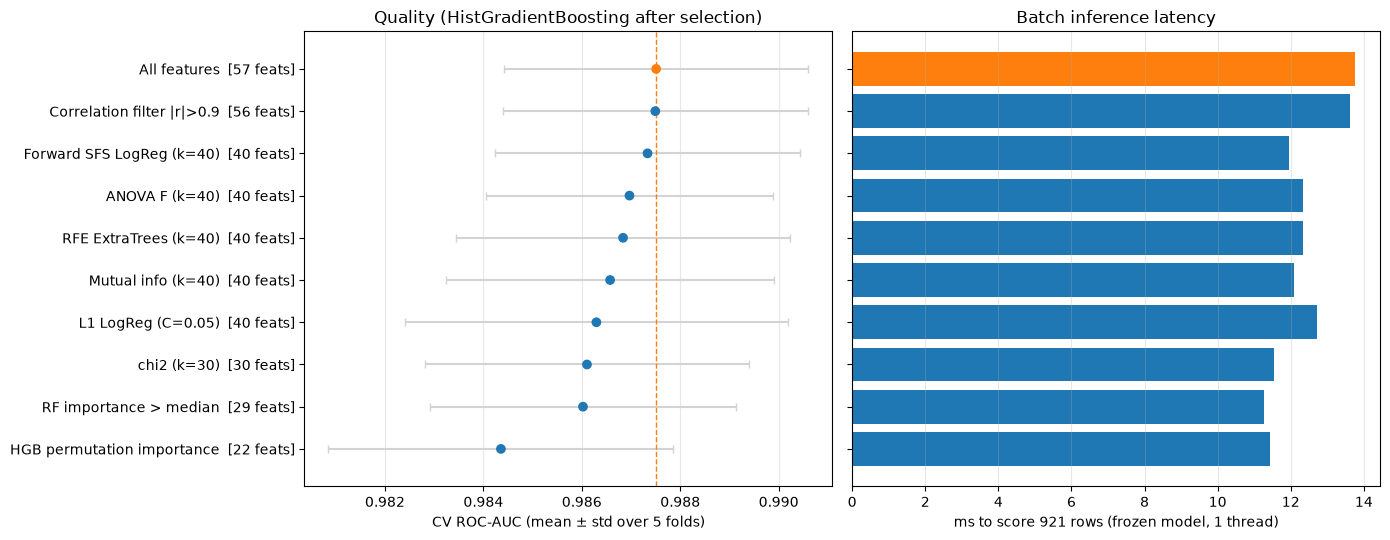

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
order = cmp_df.sort_values("roc_auc")
labels = [f"{n}  [{r.n_features:.0f} feats]" for n, r in order.iterrows()]
colors = ["tab:orange" if n == "All features" else "tab:blue" for n in order.index]
ax = axes[0]
ax.errorbar(order.roc_auc, labels, xerr=order.roc_auc_std, fmt="none", ecolor="lightgrey", capsize=3)
ax.scatter(order.roc_auc, labels, c=colors, zorder=3)
ax.axvline(base.roc_auc, ls="--", c="tab:orange", lw=1)
ax.set(xlabel="CV ROC-AUC (mean ± std over 5 folds)", title="Quality (HistGradientBoosting after selection)")
ax.grid(alpha=.3, axis="x")

ax = axes[1]
ax.barh(labels, order.batch_ms, color=colors)
ax.set(xlabel="ms to score 921 rows (frozen model, 1 thread)", title="Batch inference latency")
ax.grid(alpha=.3, axis="x")
fig.tight_layout(); fig.savefig(FIGS / "method_comparison.png", dpi=150); plt.show()

## 6. Selection stability

A feature set that changes completely when the training data shifts slightly is a maintenance problem in production (feature pipelines, monitoring, documentation all churn).
Stability = mean pairwise **Jaccard similarity** of the feature sets chosen on the 5 CV training folds (1.0 = identical every time).

In [12]:
def jaccard_stability(fold_pipes):
    sets = [set(selected_names(p)) for p in fold_pipes]
    pairs = [(a, b) for i, a in enumerate(sets) for b in sets[i + 1:]]
    return float(np.mean([len(a & b) / len(a | b) for a, b in pairs]))

cmp_df["stability"] = [jaccard_stability(results[n]["_folds"]) for n in cmp_df.index]
cmp_df.to_csv(REPORTS / "method_comparison.csv")
cmp_df[["n_features", "roc_auc", "stability"]].sort_values("stability", ascending=False)

,n_features,roc_auc,stability
All features,57.0,0.9875,1.0000
Correlation filter |r|>0.9,55.6,0.9875,0.9893
RFE ExtraTrees (k=40),40.0,0.9868,0.9659
chi2 (k=30),30.0,0.9861,0.9359
RF importance > median,29.0,0.9860,0.9338
ANOVA F (k=40),40.0,0.9870,0.9282
L1 LogReg (C=0.05),40.0,0.9863,0.8871
Mutual info (k=40),40.0,0.9866,0.8359
Forward SFS LogReg (k=40),40.0,0.9873,0.7188
HGB permutation importance,22.2,0.9844,0.6868


## 7. Pick a winner with an explicit rule, then open the test set once

Rule (decided **before** looking at the test set):
1. Keep methods whose CV AUC is within one standard error of the best method.
2. Among those, keep only methods with stability ≥ 0.7.
3. Pick the one with the fewest features (cheapest to compute, log and monitor); break ties by stability, then AUC.

Then compare the winner with the all-features model on the locked test set, with a **paired bootstrap** (2,000 resamples) of the AUC difference.

In [13]:
best = cmp_df.roc_auc.idxmax()
se_best = cmp_df.loc[best, "roc_auc_std"] / np.sqrt(CV.get_n_splits())
eligible = cmp_df[(cmp_df.roc_auc >= cmp_df.loc[best, "roc_auc"] - se_best) & (cmp_df.stability >= 0.7)]
winner = eligible.sort_values(["n_features", "stability", "roc_auc"], ascending=[True, False, False]).index[0]
print(f"best CV AUC: {best} ({cmp_df.loc[best, 'roc_auc']:.4f}), 1-SE threshold {cmp_df.loc[best, 'roc_auc'] - se_best:.4f}")
print("eligible:", list(eligible.index))
print("WINNER:", winner)

best CV AUC: All features (0.9875), 1-SE threshold 0.9861
eligible: ['All features', 'Correlation filter |r|>0.9', 'Forward SFS LogReg (k=40)', 'ANOVA F (k=40)', 'RFE ExtraTrees (k=40)', 'Mutual info (k=40)', 'L1 LogReg (C=0.05)']
WINNER: RFE ExtraTrees (k=40)


In [14]:
def test_metrics(pipe):  # evaluated on the frozen serving model = what would be deployed
    p = pipe.predict_proba(X_test)[:, 1]; yhat = (p >= 0.5).astype(int)
    return {"roc_auc": roc_auc_score(y_test, p), "f1": f1_score(y_test, yhat), "accuracy": accuracy_score(y_test, yhat),
            "precision": precision_score(y_test, yhat), "recall": recall_score(y_test, yhat)}, p

final_rows, probs = {}, {}
for name in ["All features", winner]:
    final_rows[name], probs[name] = test_metrics(serving[name])
    final_rows[name]["n_features"] = n_selected(final_pipes[name])
    final_rows[name]["batch_ms"] = cmp_df.loc[name, "batch_ms"]
    final_rows[name]["model_kb"] = cmp_df.loc[name, "model_kb"]
test_df = pd.DataFrame(final_rows).T

rng = np.random.default_rng(SEED)
yt = y_test.to_numpy(); diffs = []
for _ in range(2000):
    i = rng.integers(0, len(yt), len(yt))
    if yt[i].min() == yt[i].max():
        continue
    diffs.append(roc_auc_score(yt[i], probs[winner][i]) - roc_auc_score(yt[i], probs["All features"][i]))
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f"test AUC difference (winner - all features): {np.mean(diffs):+.4f}  95% CI [{lo:+.4f}, {hi:+.4f}]")
test_df

test AUC difference (winner - all features): -0.0013  95% CI [-0.0030, +0.0003]


,roc_auc,f1,accuracy,precision,recall,n_features,batch_ms,model_kb
All features,0.9867,0.9352,0.9490,0.9365,0.9339,57.0,13.7541,758.4463
RFE ExtraTrees (k=40),0.9855,0.9328,0.9468,0.9290,0.9366,40.0,12.3217,744.1318


In [15]:
winner_features = list(selected_names(final_pipes[winner]))
(REPORTS / "selected_features.txt").write_text("\n".join(winner_features) + "\n")
with open(MODELS / "feature_selected_hgb.pkl", "wb") as f:
    pickle.dump(serving[winner], f)

a, w = test_df.loc["All features"], test_df.loc[winner]
summary = f'''# Feature selection — final result (generated by Feature_Selection_Extended.ipynb)

Winner by the pre-registered rule: **{winner}** ({len(winner_features)} of {len(FEATURES)} features).

| model | features | test ROC-AUC | F1 | accuracy | batch latency (ms) | model size (KB) |
|---|---|---|---|---|---|---|
| All features | {int(a.n_features)} | {a.roc_auc:.4f} | {a.f1:.4f} | {a.accuracy:.4f} | {a.batch_ms:.1f} | {a.model_kb:.0f} |
| {winner} | {int(w.n_features)} | {w.roc_auc:.4f} | {w.f1:.4f} | {w.accuracy:.4f} | {w.batch_ms:.1f} | {w.model_kb:.0f} |

Paired bootstrap of test AUC difference (winner − all): {np.mean(diffs):+.4f}, 95% CI [{lo:+.4f}, {hi:+.4f}].

Selected features: {", ".join(f"`{f}`" for f in winner_features)}
'''
(REPORTS / "final_result.md").write_text(summary)
print(summary)

# Feature selection — final result (generated by Feature_Selection_Extended.ipynb)

Winner by the pre-registered rule: **RFE ExtraTrees (k=40)** (40 of 57 features).

| model | features | test ROC-AUC | F1 | accuracy | batch latency (ms) | model size (KB) |
|---|---|---|---|---|---|---|
| All features | 57 | 0.9867 | 0.9352 | 0.9490 | 13.8 | 758 |
| RFE ExtraTrees (k=40) | 40 | 0.9855 | 0.9328 | 0.9468 | 12.3 | 744 |

Paired bootstrap of test AUC difference (winner − all): -0.0013, 95% CI [-0.0030, +0.0003].

Selected features: `word_freq_make`, `word_freq_address`, `word_freq_all`, `word_freq_our`, `word_freq_over`, `word_freq_remove`, `word_freq_internet`, `word_freq_order`, `word_freq_mail`, `word_freq_receive`, `word_freq_will`, `word_freq_people`, `word_freq_addresses`, `word_freq_free`, `word_freq_business`, `word_freq_email`, `word_freq_you`, `word_freq_credit`, `word_freq_your`, `word_freq_000`, `word_freq_money`, `word_freq_hp`, `word_freq_hpl`, `word_freq_george`, `word_freq_

## Takeaways

* **Leakage is the biggest bug in the original lab**, not the choice of method: selecting on all rows produced a high AUC on pure noise (section 1b).
* On a 114-row test set, the original lab's method ranking was within noise (section 1a). CV mean ± std plus one locked test set fixes that.
* **No selection method beat all 57 features** for HistGradientBoosting (best CV AUC = all features, 0.9875). Selection is a *cost* decision, not an accuracy one.
* The winner (RFE with ExtraTrees, 40 features, stability 0.97) is statistically indistinguishable from all features on the locked test set
  (AUC difference −0.0013, 95% CI [−0.0030, +0.0003]) while dropping 30% of the inputs that production has to compute, log and monitor.
* **Measured performance gains are modest for this model**: retraining time falls ~25–45% (0.51 s → 0.30–0.38 s), single-row latency ~5–10%, model size ~2–4%.
  HistGradientBoosting's cost is driven by the number of trees, not the number of columns.
* **The biggest performance win was freezing the selector**: shipping a column list instead of the fitted selection pipeline cut the RF-importance
  pipeline's batch latency ~3.5× (≈38 ms → 11 ms) and the RFE pipeline from ≈24 MB to ≈0.7 MB on disk.
* Stability separates methods that AUC can't: SFS (0.72) and HGB permutation importance (0.69) pick noticeably different features on each fold; SFS is also ~15× slower to run.
* Fixed `k=20` is arbitrary; a CV sweep with the 1-SE rule gives a defensible `k` per method.

Artifacts written: `reports/k_sweep.csv`, `reports/method_comparison.csv`, `reports/final_result.md`, `reports/selected_features.txt`, `reports/figures/*.png`, `models/feature_selected_hgb.pkl` (git-ignored).